# A4 - LLM Agreement

This notebook compares the basic and enhanced LLM codes with the human codes, at the turn level, for two observations reported side by side:

- **OBS_26-0498, segments c and d (test).** Not used to develop the codebook; this is the main result.
- **OBS_26-0515, segments a and b (calibration).** Used to calibrate the codebook, so agreement here may be optimistic for the human codes. The LLM prompt's examples come from OBS_26-0498 a and b, not from this observation.

The two observations are never pooled. All inputs are code-only files in the repository (`results/comparison_data/analysis_table.csv` and `Data/human_coding/normalized/`), so the notebook runs without the transcripts. Run it from the top of the repository. Outputs go to `results/llm_agreement/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("analysis")
from irr_semantic import cohens_kappa
from a4_turns import (
    TEST, CALIBRATION, OBSERVATIONS, SAMPLE_LABELS, CODERS, SELF_LEVELS, OTHER_LEVELS, CODED_WHOSE,
    NORMALIZED_FOLDER, clean, last_code, load_table, coder_codes, adjudicated_codes, make_reference,
    llm_labels, enhanced_code,
)

OUTPUT_DIR = Path("results") / "llm_agreement"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and normalize the codes

`analysis_table.csv` has one row per transcript line, with each coder's codes, the adjudicated codes, and both LLM outputs aligned on the same `row` IDs. Adult lines are dropped before anything is compared.

Each coder's codes are normalized with the rules in `analysis/irr_semantic.py`, which apply codebook rules one coder had not yet applied (for example, an answer to the teacher is Self), so rule differences are not counted as disagreements. For OBS_26-0498 this reproduces the normalized files the IRR script wrote; for OBS_26-0515 it applies the same rules to our codes. The LLM outputs are not normalized, because they are what we are evaluating.

In [2]:
table = load_table()

coders = {}
normalization_log = []
for observation in OBSERVATIONS:
    for coder in CODERS:
        coders[(observation, coder)] = coder_codes(table, observation, coder, normalization_log)

# The OBS_26-0498 normalization must match the IRR script's files.
for coder in CODERS:
    saved = pd.read_csv(NORMALIZED_FOLDER / f"codes_OBS_26-0498_cd_{coder}_normalized.csv",
                        keep_default_na=False, dtype=str)
    saved = saved[~saved["speaker"].str.startswith("Ms.")].reset_index(drop=True)
    assert saved[["row", "whose", "level"]].equals(coders[(TEST, coder)][1][["row", "whose", "level"]])

pd.DataFrame(normalization_log).to_csv(OUTPUT_DIR / "normalization_log.csv", index=False)

pd.DataFrame([
    {"sample": SAMPLE_LABELS[observation],
     "student lines": int(((table["observation"] == observation) & (table["is_adult"] == "False")).sum()),
     "adjudicated lines with a code": int(((table["observation"] == observation) & (table["human_final_whose"] != "")).sum())}
    for observation in OBSERVATIONS
])

,sample,student lines,adjudicated lines with a code
0,OBS_26-0498 c-d (test),63,37
1,OBS_26-0515 a-b (calibration),122,88


## 2. Clean labels and build turns

Labels are lowercased, and blank, N/A, Unclear, and "Unclear / not coded" count as not coded.

Codes are compared by **turn**. Turns always come from the **reference** (the human codes being compared against), so every rater is scored on the same units, and they never cross a segment.

- **An individual coder as reference:** the IRR rule. A turn is that coder's coded lines by one speaker up to the line where the coder recorded a Level.
- **Adjudicated codes as reference:** the same rule on the final codes, except that a turn also ends where Vishal recorded a Level. The comparison tool fills a final value only when both coders agree, so the final Level is blank wherever we disagreed and did not resolve it; without Vishal's boundaries (the IRR script's reference coder), those lines would merge into long turns that neither of us drew. The final codes themselves are not changed.

A human rater's code for a turn is the last Whose and the last Level they gave on any line of the turn. The enhanced prompt's Level is the Level of its own turn that contains the reference turn's last line, because it writes Level only on the last line of its own turns, which can fall after the end of the human turn.

The basic prompt gives every line both an explanation label and a peer-engagement label and never says Self or Other. Following `results/README.md`, we take its explanation label on turns the reference coded Self and its engagement label on turns the reference coded Other.

In [3]:
references = {}
for observation in OBSERVATIONS:
    for coder in CODERS:
        raw, normalized = coders[(observation, coder)]
        references[(observation, coder)] = make_reference(raw, normalized)
    references[(observation, "Adjudicated")] = make_reference(*adjudicated_codes(table, observation))

pd.DataFrame([
    {"sample": SAMPLE_LABELS[observation], "reference": name, "turns": len(reference["turns"]),
     "longest turn (lines)": max(len(turn) for turn in reference["turns"])}
    for (observation, name), reference in references.items()
])

,sample,reference,turns,longest turn (lines)
0,OBS_26-0498 c-d (test),Vishal,26,3
1,OBS_26-0498 c-d (test),Caesar,34,4
2,OBS_26-0498 c-d (test),Adjudicated,31,3
3,OBS_26-0515 a-b (calibration),Vishal,25,9
4,OBS_26-0515 a-b (calibration),Caesar,82,1
5,OBS_26-0515 a-b (calibration),Adjudicated,46,7


## 3. Score each rater on the reference turns

The other human coder is included as a rater, so the LLM results can be read against human-human agreement on exactly the same turns.

For each reference and rater we report:

- **Whose agreement and κ** on turns both coded Self or Other (not available for the basic prompt). We also count reference turns the rater left not coded.
- **Level agreement on all turns**: matches out of every reference turn with a Self or Other Level. The denominator is the same for every rater, so this is the fairest number for comparing the basic and enhanced prompts. A turn the rater left uncoded, or coded on the other scale, counts as a miss.
- **Level agreement and κ on comparable turns**: only turns where the rater gave a Level on the same scale (for raters with Whose, the same Whose). This matches the definition used in the human IRR.

In [4]:
def rate_enhanced(observation):
    labels = llm_labels(table, observation)
    return lambda rows, reference_whose: enhanced_code(labels, rows)


def rate_basic(observation):
    labels = llm_labels(table, observation)

    def rate(rows, reference_whose):
        column = "basic_explanation" if reference_whose == "self" else "basic_peer_engagement"
        return None, last_code(labels[column][rows])
    return rate


def rate_human(observation, coder):
    codes = coders[(observation, coder)][1].set_index("row")
    whose, level = codes["whose"].map(clean), codes["level"].map(clean)
    return lambda rows, reference_whose: (last_code(whose[rows]), last_code(level[rows]))


def compare(observation, reference_name, rater_name, rater):
    reference = references[(observation, reference_name)]
    records = []
    for rows in reference["turns"]:
        reference_whose = last_code(reference["whose"][rows])
        reference_level = last_code(reference["level"][rows])
        rater_whose, rater_level = rater(rows, reference_whose)
        records.append({
            "observation": observation,
            "reference": reference_name,
            "rater": rater_name,
            "turn": rows[0] if len(rows) == 1 else f"{rows[0]}-{rows[-1]}",
            "rows": " ".join(rows),
            "speaker": reference["speaker"][rows[-1]],
            "reference_whose": reference_whose,
            "reference_level": reference_level,
            "rater_whose": rater_whose,
            "rater_level": rater_level,
        })
    return pd.DataFrame(records)


comparisons = []
for observation in OBSERVATIONS:
    for reference in ["Vishal", "Caesar", "Adjudicated"]:
        comparisons.append(compare(observation, reference, "Basic LLM", rate_basic(observation)))
        comparisons.append(compare(observation, reference, "Enhanced LLM", rate_enhanced(observation)))
        if reference in CODERS:
            other = next(coder for coder in CODERS if coder != reference)
            comparisons.append(compare(observation, reference, other, rate_human(observation, other)))

turn_table = pd.concat(comparisons, ignore_index=True)
turn_table.to_csv(OUTPUT_DIR / "turn_comparison.csv", index=False)
turn_table.head()

,observation,reference,rater,turn,rows,speaker,reference_whose,reference_level,rater_whose,rater_level
0,OBS_26-0498,Vishal,Basic LLM,c5,c5,Other,self,some detail,None,some detail
1,OBS_26-0498,Vishal,Basic LLM,c10,c10,Gregorio,self,some detail,None,some detail
2,OBS_26-0498,Vishal,Basic LLM,c11,c11,Other,other,medium,None,high
3,OBS_26-0498,Vishal,Basic LLM,c12-c13,c12 c13,Gregorio,other,high,None,high
4,OBS_26-0498,Vishal,Basic LLM,c14,c14,Miguel,other,high,None,high


In [5]:
def summarize(turns):
    has_whose = turns["rater_whose"].notna().all()
    coded = turns[turns["reference_whose"].isin(CODED_WHOSE)]
    with_level = coded[coded["reference_level"] != ""]
    summary = {"reference turns": len(turns), "coded reference turns": len(coded)}

    if has_whose:
        both = coded[coded["rater_whose"].isin(CODED_WHOSE)]
        summary.update({
            "whose n": len(both),
            "whose matches": int((both["reference_whose"] == both["rater_whose"]).sum()),
            "whose kappa": cohens_kappa(both["reference_whose"], both["rater_whose"]),
            "rater left not coded": len(coded) - len(both),
        })

    summary.update({
        "level all n": len(with_level),
        "level all matches": int((with_level["reference_level"] == with_level["rater_level"]).sum()),
    })

    comparable = with_level[with_level["rater_level"] != ""]
    if has_whose:
        comparable = comparable[comparable["reference_whose"] == comparable["rater_whose"]]
    summary.update({
        "level n": len(comparable),
        "level matches": int((comparable["reference_level"] == comparable["rater_level"]).sum()),
        "level kappa": cohens_kappa(comparable["reference_level"], comparable["rater_level"]),
    })
    return summary


# Build the rows directly: the basic prompt has no Whose columns.
summary = pd.DataFrame([
    {"observation": observation, "reference": reference, "rater": rater, **summarize(turns)}
    for (observation, reference, rater), turns
    in turn_table.groupby(["observation", "reference", "rater"], sort=False)
])

for prefix in ["whose", "level all", "level"]:
    summary[f"{prefix} agreement"] = summary[f"{prefix} matches"] / summary[f"{prefix} n"]

summary.to_csv(OUTPUT_DIR / "agreement_summary.csv", index=False)
summary

,observation,reference,rater,reference turns,coded reference turns,level all n,level all matches,level n,level matches,level kappa,whose n,whose matches,whose kappa,rater left not coded,whose agreement,level all agreement,level agreement
0,OBS_26-0498,Vishal,Basic LLM,26,26,26,15,26,15,0.481884,NaN,NaN,NaN,NaN,NaN,0.576923,0.576923
1,OBS_26-0498,Vishal,Enhanced LLM,26,26,26,11,19,11,0.503268,25.0,19.0,0.522293,1.0,0.760000,0.423077,0.578947
2,OBS_26-0498,Vishal,Caesar,26,26,26,11,19,11,0.488215,24.0,19.0,0.552239,2.0,0.791667,0.423077,0.578947
3,OBS_26-0498,Caesar,Basic LLM,34,28,27,15,27,15,0.439446,NaN,NaN,NaN,NaN,NaN,0.555556,0.555556
4,OBS_26-0498,Caesar,Enhanced LLM,34,28,27,12,18,12,0.584615,24.0,19.0,0.565217,4.0,0.791667,0.444444,0.666667
5,OBS_26-0498,Caesar,Vishal,34,28,27,11,19,11,0.488215,26.0,20.0,0.503185,2.0,0.769231,0.407407,0.578947
6,OBS_26-0498,Adjudicated,Basic LLM,31,31,29,10,26,10,0.261101,NaN,NaN,NaN,NaN,NaN,0.344828,0.384615
7,OBS_26-0498,Adjudicated,Enhanced LLM,31,31,29,11,22,11,0.414044,28.0,23.0,0.642857,3.0,0.821429,0.379310,0.500000
8,OBS_26-0515,Vishal,Basic LLM,25,25,25,7,24,7,0.114967,NaN,NaN,NaN,NaN,NaN,0.280000,0.291667
9,OBS_26-0515,Vishal,Enhanced LLM,25,25,25,4,10,4,0.294118,20.0,10.0,0.137931,5.0,0.500000,0.160000,0.400000


**Check against the human IRR.** Scoring Caesar on Vishal's turns in OBS_26-0498 should reproduce `Data/human_coding/normalized/irr_summary_OBS_26-0498_cd.csv`.

In [6]:
irr = pd.read_csv(NORMALIZED_FOLDER / "irr_summary_OBS_26-0498_cd.csv")
human_pair = summary[(summary["observation"] == TEST) & (summary["reference"] == "Vishal")
                     & (summary["rater"] == "Caesar")].iloc[0]

assert human_pair["whose n"] == irr.loc[0, "units"]
assert np.isclose(human_pair["whose kappa"], irr.loc[0, "kappa"], atol=0.001)
assert human_pair["level n"] == irr.loc[1, "units"]
assert np.isclose(human_pair["level kappa"], irr.loc[1, "kappa"], atol=0.001)
print("Matches the human IRR summary.")

Matches the human IRR summary.


## 4. Agreement table

A readable version of the summary, saved as CSV and as an image. "k/n" gives matches over the denominator.

In [7]:
def fraction(matches, n):
    return "" if pd.isna(n) else f"{int(matches)}/{int(n)} ({matches / n:.0%})" if n else "0/0"


def kappa_text(value):
    return "" if pd.isna(value) else f"{value:.2f}"


agreement_table = pd.DataFrame({
    "Sample": summary["observation"].map(SAMPLE_LABELS),
    "Reference": summary["reference"],
    "Rater": summary["rater"],
    "Whose agreement": [fraction(m, n) if not pd.isna(n) else "n/a (no Whose)"
                        for m, n in zip(summary["whose matches"], summary["whose n"])],
    "Whose κ": summary["whose kappa"].map(kappa_text),
    "Not coded by rater": summary["rater left not coded"].map(lambda x: "" if pd.isna(x) else int(x)),
    "Level, all turns": [fraction(m, n) for m, n in zip(summary["level all matches"], summary["level all n"])],
    "Level, comparable turns": [fraction(m, n) for m, n in zip(summary["level matches"], summary["level n"])],
    "Level κ": summary["level kappa"].map(kappa_text),
})
agreement_table.to_csv(OUTPUT_DIR / "agreement_table.csv", index=False)
agreement_table

,Sample,Reference,Rater,Whose agreement,Whose κ,Not coded by rater,"Level, all turns","Level, comparable turns",Level κ
0,OBS_26-0498 c-d (test),Vishal,Basic LLM,n/a (no Whose),,,15/26 (58%),15/26 (58%),0.48
1,OBS_26-0498 c-d (test),Vishal,Enhanced LLM,19/25 (76%),0.52,1,11/26 (42%),11/19 (58%),0.50
2,OBS_26-0498 c-d (test),Vishal,Caesar,19/24 (79%),0.55,2,11/26 (42%),11/19 (58%),0.49
3,OBS_26-0498 c-d (test),Caesar,Basic LLM,n/a (no Whose),,,15/27 (56%),15/27 (56%),0.44
4,OBS_26-0498 c-d (test),Caesar,Enhanced LLM,19/24 (79%),0.57,4,12/27 (44%),12/18 (67%),0.58
5,OBS_26-0498 c-d (test),Caesar,Vishal,20/26 (77%),0.50,2,11/27 (41%),11/19 (58%),0.49
6,OBS_26-0498 c-d (test),Adjudicated,Basic LLM,n/a (no Whose),,,10/29 (34%),10/26 (38%),0.26
7,OBS_26-0498 c-d (test),Adjudicated,Enhanced LLM,23/28 (82%),0.64,3,11/29 (38%),11/22 (50%),0.41
8,OBS_26-0515 a-b (calibration),Vishal,Basic LLM,n/a (no Whose),,,7/25 (28%),7/24 (29%),0.11
9,OBS_26-0515 a-b (calibration),Vishal,Enhanced LLM,10/20 (50%),0.14,5,4/25 (16%),4/10 (40%),0.29


In [8]:
def save_table_image(frame, path, title, font_size=9):
    figure, axis = plt.subplots(figsize=(4, 0.3 * (len(frame) + 2)))
    axis.axis("off")
    shown = axis.table(
        cellText=frame.astype(str).values,
        colLabels=frame.columns,
        cellLoc="left",
        colLoc="left",
        loc="upper left",
    )
    shown.auto_set_font_size(False)
    shown.set_fontsize(font_size)
    shown.auto_set_column_width(list(range(frame.shape[1])))
    shown.scale(1, 1.4)
    for (row, column), cell in shown.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        if row == 0:
            cell.set_facecolor("#eef2f7")
            cell.set_text_props(weight="bold")
    axis.set_title(title, loc="left", fontsize=11, weight="bold")
    figure.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(figure)


save_table_image(agreement_table, OUTPUT_DIR / "agreement_table.png",
                 "Turn-level agreement between LLM and human codes")

## 5. Agreement bars

One row per observation. Each group is one human reference. The other human coder is shown as a benchmark: an LLM bar near the human bar agrees with that reference about as well as the other person did.

- **Whose** is computed on turns both coded Self or Other; the basic prompt has no Whose label.
- **Level** uses all reference turns with a Level, so the denominator is the same for every rater in a group.

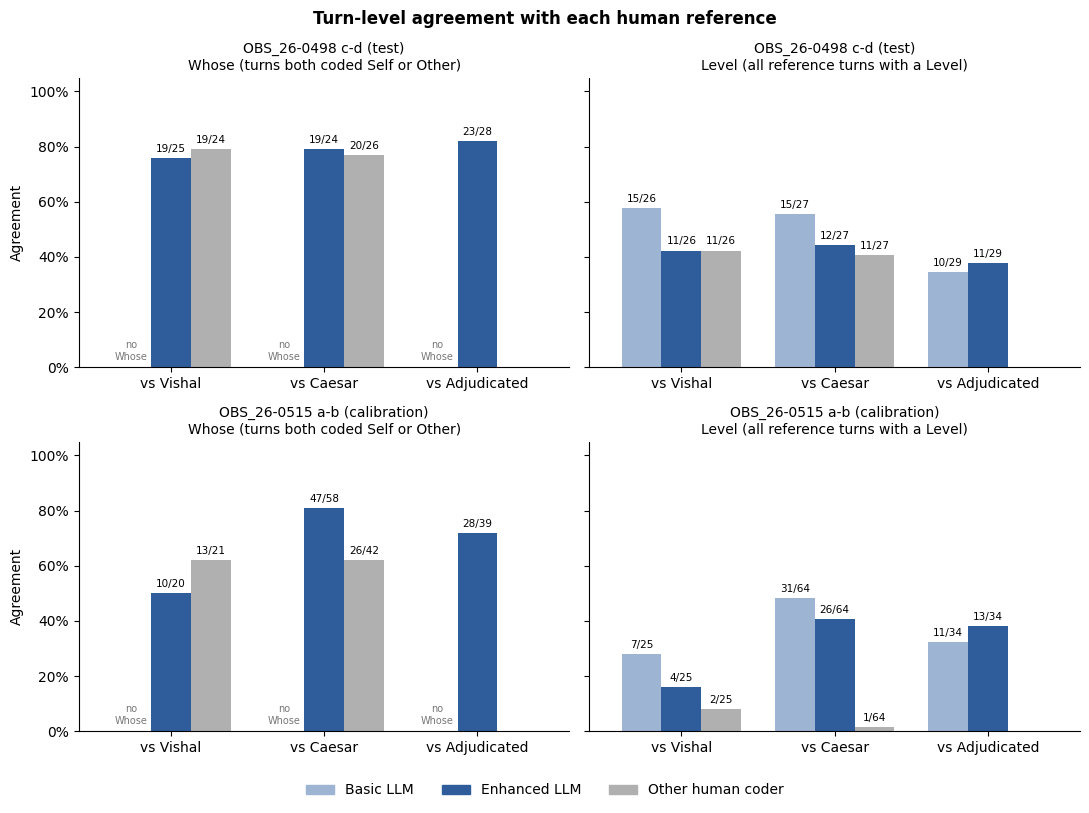

In [9]:
RATER_ORDER = ["Basic LLM", "Enhanced LLM", "Other human coder"]
RATER_COLORS = {"Basic LLM": "#9db4d3", "Enhanced LLM": "#2f5d9b", "Other human coder": "#b0b0b0"}
REFERENCE_ORDER = ["Vishal", "Caesar", "Adjudicated"]
PANELS = [("whose", "Whose (turns both coded Self or Other)"),
          ("level all", "Level (all reference turns with a Level)")]

bar_summary = summary.copy()
bar_summary["rater group"] = np.where(bar_summary["rater"].isin(CODERS), "Other human coder", bar_summary["rater"])

figure, axes = plt.subplots(len(OBSERVATIONS), 2, figsize=(11, 4 * len(OBSERVATIONS)), sharey=True)
width = 0.26

for row_axes, observation in zip(axes, OBSERVATIONS):
    observation_summary = bar_summary[bar_summary["observation"] == observation]
    for axis, (prefix, title) in zip(row_axes, PANELS):
        for offset, rater in enumerate(RATER_ORDER):
            for position, reference in enumerate(REFERENCE_ORDER):
                match = observation_summary[(observation_summary["reference"] == reference)
                                            & (observation_summary["rater group"] == rater)]
                x = position + (offset - 1) * width
                if match.empty:
                    continue
                result = match.iloc[0]
                if pd.isna(result[f"{prefix} n"]):
                    axis.text(x, 0.02, "no\nWhose", ha="center", va="bottom", fontsize=7, color="#777777")
                    continue
                axis.bar(x, result[f"{prefix} agreement"], width, color=RATER_COLORS[rater])
                axis.text(x, result[f"{prefix} agreement"] + 0.015,
                          f"{int(result[f'{prefix} matches'])}/{int(result[f'{prefix} n'])}",
                          ha="center", va="bottom", fontsize=7.5)
        axis.set_xlim(-0.6, len(REFERENCE_ORDER) - 0.4)
        axis.set_xticks(range(len(REFERENCE_ORDER)))
        axis.set_xticklabels([f"vs {reference}" for reference in REFERENCE_ORDER])
        axis.set_title(f"{SAMPLE_LABELS[observation]}\n{title}", fontsize=10)
        axis.set_ylim(0, 1.05)
        axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
        axis.spines[["top", "right"]].set_visible(False)
    row_axes[0].set_ylabel("Agreement")

handles = [plt.Rectangle((0, 0), 1, 1, color=RATER_COLORS[rater]) for rater in RATER_ORDER]
figure.legend(handles, RATER_ORDER, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))
figure.suptitle("Turn-level agreement with each human reference", fontsize=12, weight="bold")
figure.tight_layout(rect=(0, 0.03, 1, 1))
figure.savefig(OUTPUT_DIR / "agreement_bars.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Confusion matrices

Against the adjudicated codes. Rows are the adjudicated label and columns are the LLM label for the same turn, so the diagonal is agreement.

- **Whose** (enhanced prompt only), one panel per observation.
- **Level on Self turns** and **Level on Other turns**, for both prompts, one figure per observation. "Other scale" or "Self scale" means the enhanced prompt coded the turn with the other Whose, so its Level is on the other scale.

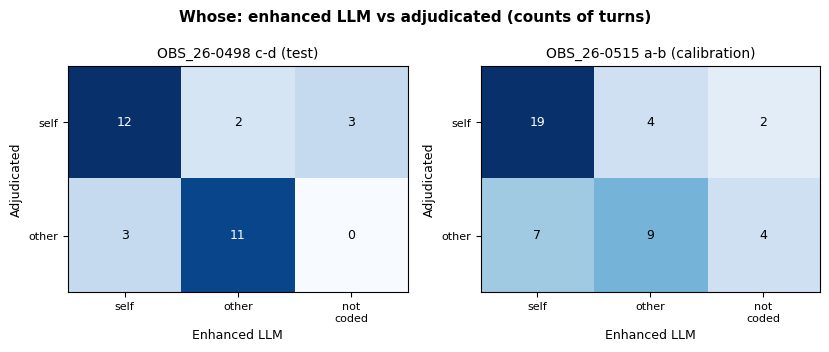

In [10]:
def confusion(turns, row_labels, column_labels, column_map=lambda label: label):
    columns = turns["rater_value"].map(column_map)
    counts = pd.crosstab(turns["reference_value"], columns)
    return counts.reindex(index=row_labels, columns=column_labels, fill_value=0)


def plot_confusion(axis, counts, title, xlabel, ylabel):
    values = counts.values
    axis.imshow(values, cmap="Blues", vmin=0, vmax=max(values.max(), 1))
    for (i, j), value in np.ndenumerate(values):
        axis.text(j, i, value, ha="center", va="center", fontsize=9,
                  color="white" if value > values.max() / 2 else "black")
    axis.set_xticks(range(counts.shape[1]))
    axis.set_xticklabels([label.replace(" ", "\n", 1) for label in counts.columns], fontsize=8)
    axis.set_yticks(range(counts.shape[0]))
    axis.set_yticklabels(counts.index, fontsize=8)
    axis.set_xlabel(xlabel, fontsize=9)
    axis.set_ylabel(ylabel, fontsize=9)
    axis.set_title(title, fontsize=10)


def with_values(turns, column):
    turns = turns.copy()
    turns["reference_value"] = turns[f"reference_{column}"]
    turns["rater_value"] = turns[f"rater_{column}"].replace("", "not coded")
    return turns


adjudicated = turn_table[turn_table["reference"] == "Adjudicated"]

figure, axes = plt.subplots(1, len(OBSERVATIONS), figsize=(4.2 * len(OBSERVATIONS), 3.4))
for axis, observation in zip(axes, OBSERVATIONS):
    enhanced = adjudicated[(adjudicated["observation"] == observation) & (adjudicated["rater"] == "Enhanced LLM")]
    counts = confusion(with_values(enhanced[enhanced["reference_whose"].isin(CODED_WHOSE)], "whose"),
                       CODED_WHOSE, CODED_WHOSE + ["not coded"])
    plot_confusion(axis, counts, SAMPLE_LABELS[observation], "Enhanced LLM", "Adjudicated")
figure.suptitle("Whose: enhanced LLM vs adjudicated (counts of turns)", fontsize=11, weight="bold")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "confusion_whose.png", dpi=200, bbox_inches="tight")
plt.show()

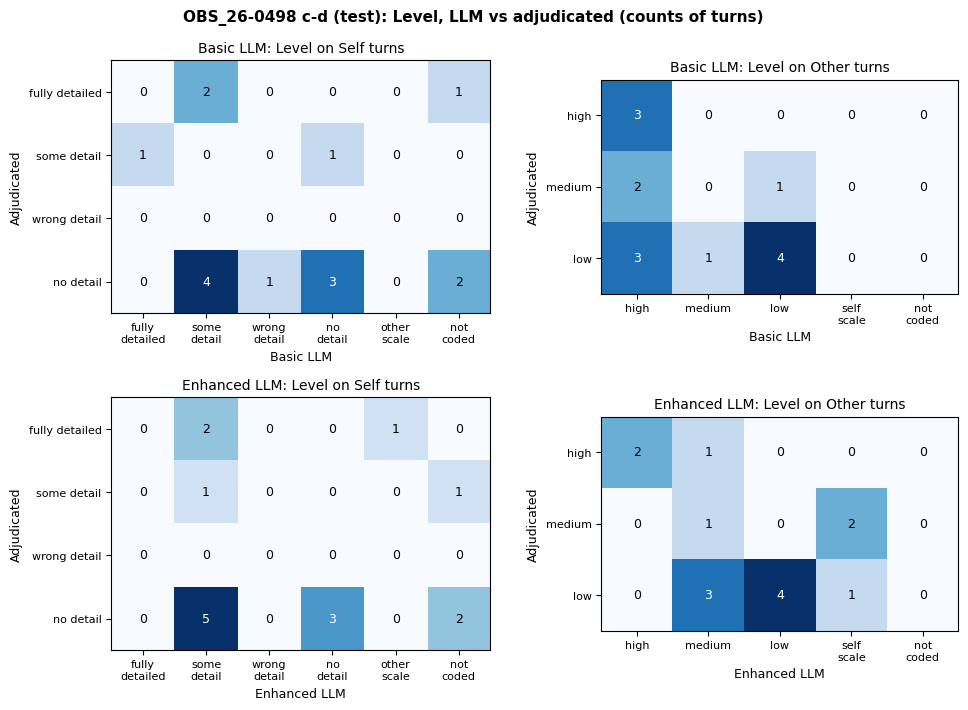

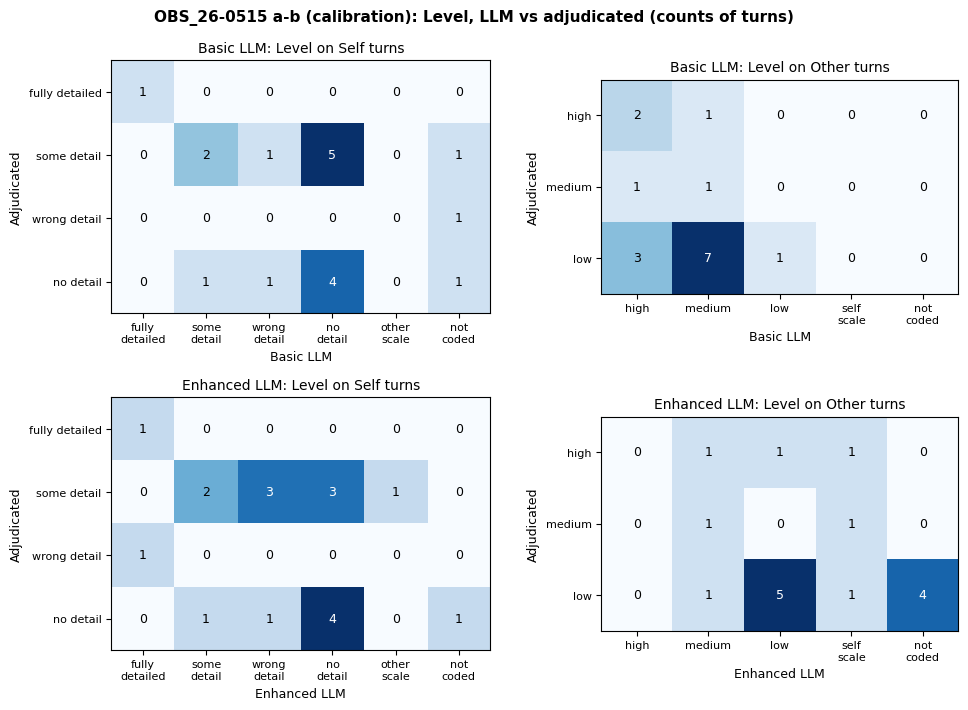

In [11]:
def scale_map(other_levels, other_name):
    return lambda label: other_name if label in other_levels else label


LEVEL_PANELS = [
    ("self", SELF_LEVELS, SELF_LEVELS + ["other scale", "not coded"], scale_map(OTHER_LEVELS, "other scale")),
    ("other", OTHER_LEVELS, OTHER_LEVELS + ["self scale", "not coded"], scale_map(SELF_LEVELS, "self scale")),
]

for observation in OBSERVATIONS:
    figure, axes = plt.subplots(2, 2, figsize=(10, 7.2), gridspec_kw={"width_ratios": [6, 5]})
    for row, rater in enumerate(["Basic LLM", "Enhanced LLM"]):
        turns = adjudicated[(adjudicated["observation"] == observation) & (adjudicated["rater"] == rater)
                            & (adjudicated["reference_level"] != "")]
        for column, (whose, row_labels, column_labels, column_map) in enumerate(LEVEL_PANELS):
            subset = with_values(turns[turns["reference_whose"] == whose], "level")
            counts = confusion(subset, row_labels, column_labels, column_map)
            plot_confusion(axes[row, column], counts, f"{rater}: Level on {whose.capitalize()} turns",
                           rater, "Adjudicated")
    figure.suptitle(f"{SAMPLE_LABELS[observation]}: Level, LLM vs adjudicated (counts of turns)",
                    fontsize=11, weight="bold")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / f"confusion_level_{observation}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7. Disagreement cases

For each observation, turns where the enhanced prompt differs from the adjudicated codes on Whose or Level, with the basic prompt's label for the same turn. Row IDs join back to the transcript for the qualitative reading.

In [12]:
def code_text(whose, level):
    whose = whose or "not coded"
    return f"{whose} / {level}" if level else whose


for observation in OBSERVATIONS:
    turns = adjudicated[adjudicated["observation"] == observation]
    paired = (
        turns[turns["rater"] == "Enhanced LLM"]
        .merge(turns[turns["rater"] == "Basic LLM"][["turn", "rater_level"]], on="turn", suffixes=("", "_basic"))
    )
    paired["Adjudicated"] = [code_text(w, l) for w, l in zip(paired["reference_whose"], paired["reference_level"])]
    paired["Enhanced LLM"] = [code_text(w, l) for w, l in zip(paired["rater_whose"], paired["rater_level"])]
    paired["Basic LLM level"] = paired["rater_level_basic"].replace("", "not coded")
    paired["Difference"] = np.select(
        [paired["reference_whose"] == "",
         paired["rater_whose"] == "",
         paired["reference_whose"] != paired["rater_whose"],
         (paired["reference_level"] != "") & (paired["reference_level"] != paired["rater_level"])],
        ["", "Not coded by LLM", "Whose", "Level"],
        default="",
    )
    disagreements = (
        paired[paired["Difference"] != ""]
        [["turn", "speaker", "Adjudicated", "Enhanced LLM", "Basic LLM level", "Difference"]]
        .rename(columns={"turn": "Turn", "speaker": "Speaker"})
        .reset_index(drop=True)
    )
    disagreements.to_csv(OUTPUT_DIR / f"disagreements_enhanced_vs_adjudicated_{observation}.csv", index=False)
    save_table_image(
        disagreements,
        OUTPUT_DIR / f"disagreements_enhanced_vs_adjudicated_{observation}.png",
        f"{SAMPLE_LABELS[observation]}: {len(disagreements)} of {len(paired)} adjudicated turns where the enhanced LLM differs",
    )
    display(disagreements)

,Turn,Speaker,Adjudicated,Enhanced LLM,Basic LLM level,Difference
0,c5,Other,self / no detail,self / some detail,some detail,Level
1,c10,Gregorio,other / low,other / medium,high,Level
2,c11,Other,other / medium,self / some detail,high,Whose
3,c16,Gregorio,other / low,other / medium,high,Level
4,c17,Other,other / low,other / medium,high,Level
5,c23,Gregorio,self / no detail,not coded,no detail,Not coded by LLM
6,c24,Miguel,other / low,self / some detail,medium,Whose
7,c28,Gregorio,other / high,other / medium,high,Level
8,c39,Other,self / no detail,not coded,not coded,Not coded by LLM
9,c38-c43,Gregorio,self,other / high,some detail,Whose


,Turn,Speaker,Adjudicated,Enhanced LLM,Basic LLM level,Difference
0,a9,Gregorio,self / wrong detail,self / fully detailed,not coded,Level
1,a10-a11,Miguel,other / high,other / low,medium,Level
2,a19-a22,Miguel,self,other / medium,no detail,Whose
3,a24-a25,Miguel,self,other / medium,no detail,Whose
4,a27,Miguel,self,other / low,not coded,Whose
5,a30,Miguel,self,not coded,not coded,Not coded by LLM
6,a45-a46,Gregorio,self / some detail,self / no detail,some detail,Level
7,a55-a56,Miguel,other,self / no detail,low,Whose
8,a57,Gregorio,other / low,not coded,medium,Not coded by LLM
9,a58,Gregorio,other / low,self / no detail,low,Whose


## Outputs

All files are in `results/llm_agreement/` and contain codes and counts only, no transcript text.

| File | Contents |
|---|---|
| `normalization_log.csv` | Every change the IRR rules made to each coder's codes, both observations |
| `turn_comparison.csv` | Every reference turn with the reference and rater codes, for every comparison |
| `agreement_summary.csv` | All counts, agreement rates, and κ values |
| `agreement_table.csv`, `agreement_table.png` | The readable agreement table |
| `agreement_bars.png` | Agreement with each human reference, one row per observation |
| `confusion_whose.png` | Whose confusion matrices, enhanced LLM vs adjudicated, both observations |
| `confusion_level_<observation>.png` | Level confusion matrices, both prompts vs adjudicated |
| `disagreements_enhanced_vs_adjudicated_<observation>.csv`, `.png` | Turns where the enhanced LLM differs from the adjudicated codes |